# 03 — Action Chunking and Temporal Modeling

In previous notebooks, we learned single-step policies:

$$
a_t = \pi_\theta(o_t)
$$

or stochastic policies:

$$
a_t \sim p_\theta(a_t \mid o_t)
$$

We now extend the prediction target to an action sequence:

$$
A_t = (a_t, a_{t+1}, \ldots, a_{t+H-1})
$$

Our goals are:

1. Build a dataset of action chunks.
2. Train a deterministic chunking policy.
3. Compare open-loop and receding-horizon execution.
4. Investigate multimodality in action sequences.

This will prepare us for latent-variable models and ACT.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from robot_learning_playground.point_robot import (
    collect_demonstrations,
    rollout,
    step,
    make_observation,
    reached_goal,
)

In [2]:
demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

print("Episodes:", len(demonstrations))

demo = demonstrations[0]

print("Observations:", demo["observations"].shape)
print("Actions:", demo["actions"].shape)
print("Positions:", demo["positions"].shape)

Episodes: 500
Observations: (25, 4)
Actions: (25, 2)
Positions: (26, 2)


In [4]:
def create_action_chunks(demonstrations, horizon=8):
    observations = []
    action_chunks = []

    for demo in demonstrations:
        obs = demo["observations"]
        actions = demo["actions"]

        T = len(actions)

        for t in range(T - horizon + 1):
            observations.append(obs[t])
            action_chunks.append(
                actions[t:t + horizon]
            )

    return (
        np.asarray(observations, dtype=np.float32),
        np.asarray(action_chunks, dtype=np.float32),
    )

In [11]:
HORIZON = 8

chunk_obs, chunk_actions = create_action_chunks(
    demonstrations,
    horizon=HORIZON,
)

print("Observations:", chunk_obs.shape)
print("Action chunks:", chunk_actions.shape)

Observations: (9268, 4)
Action chunks: (9268, 8, 2)


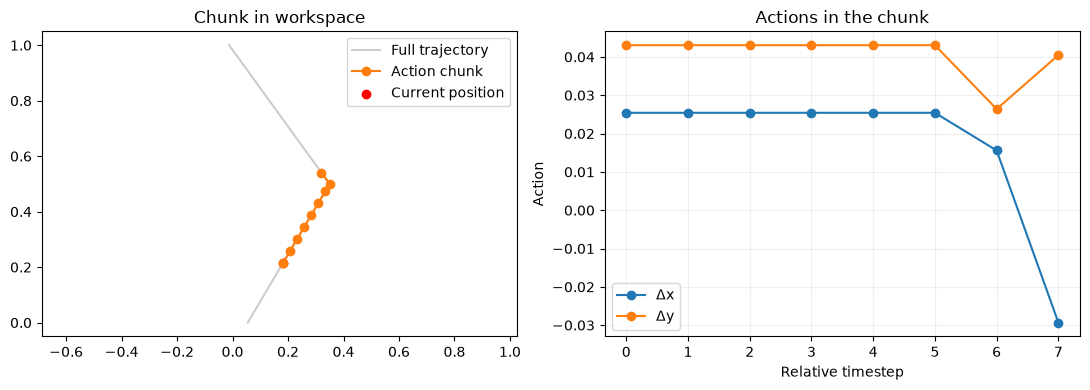

In [12]:
episode = demonstrations[0]

t = 5
H = 8

positions = episode["positions"]
actions = episode["actions"]

chunk_ep_positions = positions[t:t + H + 1]
chunk_ep_actions = actions[t:t + H]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    positions[:, 0],
    positions[:, 1],
    color="gray",
    alpha=0.4,
    label="Full trajectory",
)

axes[0].plot(
    chunk_ep_positions[:, 0],
    chunk_ep_positions[:, 1],
    "-o",
    color="tab:orange",
    label="Action chunk",
)

axes[0].scatter(
    *positions[t],
    color="red",
    label="Current position",
)

axes[0].set_title("Chunk in workspace")
axes[0].axis("equal")
axes[0].legend()

axes[1].plot(
    chunk_ep_actions[:, 0],
    "-o",
    label="Δx",
)

axes[1].plot(
    chunk_ep_actions[:, 1],
    "-o",
    label="Δy",
)

axes[1].set_xlabel("Relative timestep")
axes[1].set_ylabel("Action")
axes[1].set_title("Actions in the chunk")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Chunking Policy

In [13]:
class ChunkingMLP(nn.Module):
    def __init__(
        self,
        obs_dim=4,
        action_dim=2,
        horizon=8,
        hidden_dim=128,
    ):
        super().__init__()

        self.horizon = horizon
        self.action_dim = action_dim

        self.network = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, horizon * action_dim),
        )

    def forward(self, observations):
        output = self.network(observations)

        return output.reshape(
            -1,
            self.horizon,
            self.action_dim,
        )

In [14]:
model = ChunkingMLP(horizon=HORIZON)

test_obs = torch.randn(32, 4)
predicted_chunks = model(test_obs)

print(predicted_chunks.shape)

torch.Size([32, 8, 2])


In [15]:
print("Observations:", chunk_obs.shape)
print("Action chunks:", chunk_actions.shape)

Observations: (9268, 4)
Action chunks: (9268, 8, 2)


In [16]:
torch.manual_seed(42)

x = torch.tensor(chunk_obs, dtype=torch.float32)
y = torch.tensor(chunk_actions, dtype=torch.float32)

dataset = TensorDataset(x, y)

dataloader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True,
)

model = ChunkingMLP(
    horizon=HORIZON,
    hidden_dim=128,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

criterion = nn.MSELoss()

Epoch  10 | MSE: 0.000120
Epoch  20 | MSE: 0.000102
Epoch  30 | MSE: 0.000092
Epoch  40 | MSE: 0.000084
Epoch  50 | MSE: 0.000081
Epoch  60 | MSE: 0.000078
Epoch  70 | MSE: 0.000075
Epoch  80 | MSE: 0.000073
Epoch  90 | MSE: 0.000071
Epoch 100 | MSE: 0.000070


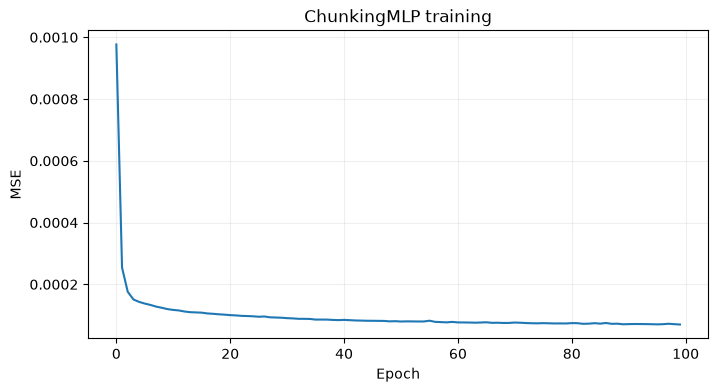

In [17]:
num_epochs = 100
loss_history = []

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0

    for batch_obs, batch_chunks in dataloader:
        predicted_chunks = model(batch_obs)

        loss = criterion(
            predicted_chunks,
            batch_chunks,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch_obs)

    epoch_loss /= len(dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"MSE: {epoch_loss:.6f}"
        )

plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("ChunkingMLP training")
plt.grid(alpha=0.2)
plt.show()

Plot a predicted chunk vs expert actions 

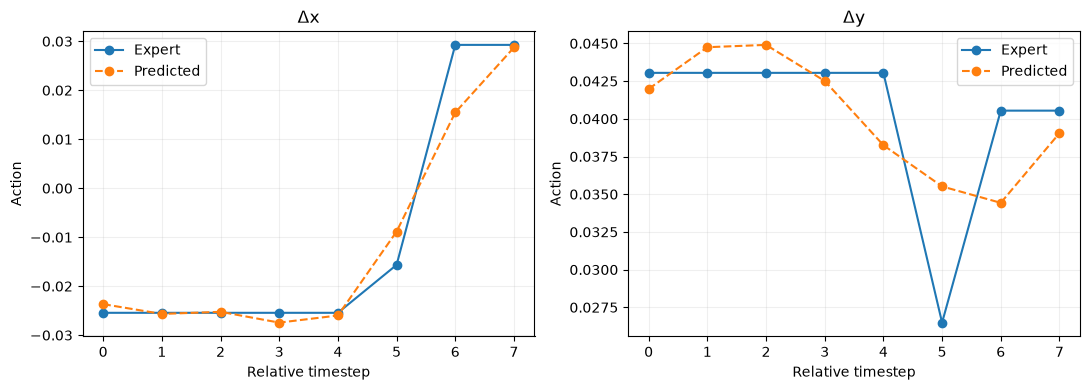

In [18]:
model.eval()

sample_idx = 100

observation = x[sample_idx:sample_idx + 1]

with torch.no_grad():
    predicted = model(observation)[0].numpy()

target = y[sample_idx].numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for i, label in enumerate(["Δx", "Δy"]):
    axes[i].plot(
        target[:, i],
        "-o",
        label="Expert",
    )

    axes[i].plot(
        predicted[:, i],
        "--o",
        label="Predicted",
    )

    axes[i].set_title(label)
    axes[i].set_xlabel("Relative timestep")
    axes[i].set_ylabel("Action")
    axes[i].legend()
    axes[i].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [19]:
def chunked_rollout(
    model,
    start,
    goal,
    horizon=8,
    execution_horizon=8,
    max_steps=100,
    goal_tolerance=0.05,
):
    assert 1 <= execution_horizon <= horizon

    position = start.copy()

    positions = [position.copy()]
    actions = []

    model.eval()

    while len(actions) < max_steps:
        if reached_goal(position, goal, goal_tolerance):
            break

        observation = make_observation(position, goal)

        obs_tensor = torch.tensor(
            observation,
            dtype=torch.float32,
        ).unsqueeze(0)

        with torch.no_grad():
            chunk = model(obs_tensor)[0].numpy()

        for action in chunk[:execution_horizon]:
            if len(actions) >= max_steps:
                break

            position = step(position, action)

            actions.append(action.copy())
            positions.append(position.copy())

            if reached_goal(position, goal, goal_tolerance):
                break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions).reshape(-1, 2),
    }

In [20]:
# Open-loop vs receding horizon chunked rollout
START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

trajectory_open = chunked_rollout(
    model,
    START,
    GOAL,
    horizon=HORIZON,
    execution_horizon=8,
)

trajectory_receding = chunked_rollout(
    model,
    START,
    GOAL,
    horizon=HORIZON,
    execution_horizon=2,
)

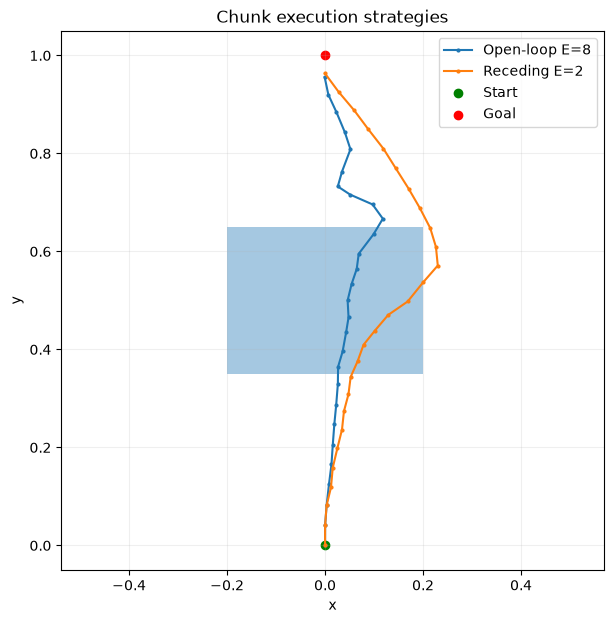

In [22]:
from robot_learning_playground.point_robot import OBSTACLE

plt.figure(figsize=(7, 7))

for trajectory, label in [
    (trajectory_open, "Open-loop E=8"),
    (trajectory_receding, "Receding E=2"),
]:
    positions = trajectory["positions"]

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        "-o",
        markersize=2,
        label=label,
    )

rect = plt.Rectangle(
    (OBSTACLE["xmin"], OBSTACLE["ymin"]),
    OBSTACLE["xmax"] - OBSTACLE["xmin"],
    OBSTACLE["ymax"] - OBSTACLE["ymin"],
    alpha=0.4,
)

plt.gca().add_patch(rect)

plt.scatter(*START, color="green", label="Start")
plt.scatter(*GOAL, color="red", label="Goal")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Chunk execution strategies")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [23]:
from robot_learning_playground.point_robot import (
    sample_task,
    is_collision,
)

rng = np.random.default_rng(123)

test_tasks = [
    sample_task(rng)
    for _ in range(100)
]

In [24]:
def evaluate_trajectory(trajectory, goal, tolerance=0.05):
    positions = trajectory["positions"]

    collision = any(
        is_collision(p)
        for p in positions
    )

    reached = any(
        reached_goal(p, goal, tolerance)
        for p in positions
    )

    return {
        "success": reached and not collision,
        "collision": collision,
    }

In [25]:
results = {}

for E in [1, 2, 4, 8]:
    evaluations = []
    trajectories = []

    for start, goal in test_tasks:
        trajectory = chunked_rollout(
            model,
            start,
            goal,
            horizon=HORIZON,
            execution_horizon=E,
        )

        evaluation = evaluate_trajectory(
            trajectory,
            goal,
        )

        evaluations.append(evaluation)
        trajectories.append(trajectory)

    results[E] = {
        "success_rate": np.mean([
            e["success"] for e in evaluations
        ]),
        "collision_rate": np.mean([
            e["collision"] for e in evaluations
        ]),
        "trajectories": trajectories,
    }

    print(
        f"E={E} | "
        f"Success: {results[E]['success_rate']:.1%} | "
        f"Collision: {results[E]['collision_rate']:.1%}"
    )

E=1 | Success: 57.0% | Collision: 16.0%
E=2 | Success: 59.0% | Collision: 25.0%
E=4 | Success: 42.0% | Collision: 48.0%
E=8 | Success: 0.0% | Collision: 100.0%


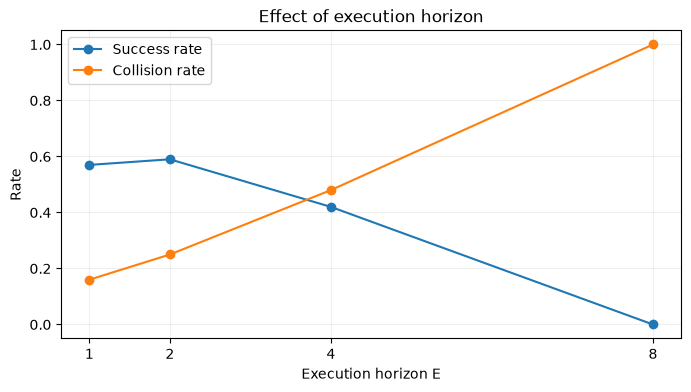

In [26]:
execution_horizons = list(results.keys())

success_rates = [
    results[E]["success_rate"]
    for E in execution_horizons
]

collision_rates = [
    results[E]["collision_rate"]
    for E in execution_horizons
]

plt.figure(figsize=(8, 4))

plt.plot(
    execution_horizons,
    success_rates,
    "-o",
    label="Success rate",
)

plt.plot(
    execution_horizons,
    collision_rates,
    "-o",
    label="Collision rate",
)

plt.xlabel("Execution horizon E")
plt.ylabel("Rate")
plt.title("Effect of execution horizon")
plt.xticks(execution_horizons)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [27]:
from robot_learning_playground.point_robot import (
    left_expert,
    right_expert,
)

START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

left_traj = rollout(
    left_expert, START, GOAL, max_steps=HORIZON
)

right_traj = rollout(
    right_expert, START, GOAL, max_steps=HORIZON
)

obs = torch.tensor(
    make_observation(START, GOAL),
    dtype=torch.float32,
).unsqueeze(0)

with torch.no_grad():
    predicted_chunk = model(obs)[0].numpy()

left_chunk = left_traj["actions"]
right_chunk = right_traj["actions"]

mean_chunk = 0.5 * (left_chunk + right_chunk)

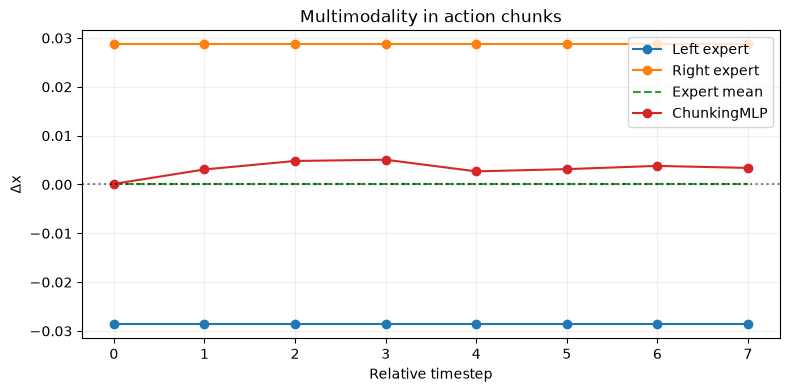

In [28]:
plt.figure(figsize=(9, 4))

plt.plot(left_chunk[:, 0], "-o", label="Left expert")
plt.plot(right_chunk[:, 0], "-o", label="Right expert")
plt.plot(mean_chunk[:, 0], "--", label="Expert mean")
plt.plot(
    predicted_chunk[:, 0],
    "-o",
    label="ChunkingMLP",
)

plt.axhline(0, color="black", linestyle=":", alpha=0.5)
plt.xlabel("Relative timestep")
plt.ylabel("Δx")
plt.title("Multimodality in action chunks")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Probabilistic Action Chunking

In [29]:
from torch.distributions import (
    Categorical,
    Normal,
    Independent,
    MixtureSameFamily,
)

class ChunkMDN(nn.Module):
    def __init__(
        self,
        obs_dim=4,
        action_dim=2,
        horizon=8,
        n_components=2,
        hidden_dim=128,
        scale=0.003,
    ):
        super().__init__()

        self.horizon = horizon
        self.action_dim = action_dim
        self.n_components = n_components
        self.scale = scale

        self.encoder = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.logits_head = nn.Linear(
            hidden_dim,
            n_components,
        )

        self.mean_head = nn.Linear(
            hidden_dim,
            n_components * horizon * action_dim,
        )

    def forward(self, observations):
        batch_size = observations.shape[0]

        h = self.encoder(observations)

        logits = self.logits_head(h)

        means = self.mean_head(h).reshape(
            batch_size,
            self.n_components,
            self.horizon * self.action_dim,
        )

        scales = torch.full_like(means, self.scale)

        components = Independent(
            Normal(loc=means, scale=scales),
            1,
        )

        return MixtureSameFamily(
            Categorical(logits=logits),
            components,
        )

In [31]:
chunk_mdn = ChunkMDN(
    horizon=HORIZON,
    n_components=2,
)

test_batch = torch.randn(32, 4)

dist = chunk_mdn(test_batch)

samples = dist.sample()

print("Sample shape:", samples.shape)
print("Log probability shape:", dist.log_prob(samples).shape)

chunks = samples.reshape(-1, HORIZON, 2)

print(chunks.shape)

Sample shape: torch.Size([32, 16])
Log probability shape: torch.Size([32])
torch.Size([32, 8, 2])


In [32]:
x = torch.tensor(
    chunk_obs,
    dtype=torch.float32,
)

# Flatten the action chunks to have shape (N, HORIZON * 2)
y = torch.tensor(
    chunk_actions,
    dtype=torch.float32,
).reshape(-1, HORIZON * 2)

dataset = TensorDataset(x, y)

dataloader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True,
)

print("Observations:", x.shape)
print("Flattened chunks:", y.shape)

Observations: torch.Size([9268, 4])
Flattened chunks: torch.Size([9268, 16])


In [33]:
torch.manual_seed(42)

chunk_mdn = ChunkMDN(
    horizon=HORIZON,
    n_components=2,
    hidden_dim=128,
    scale=0.003,
)

optimizer = torch.optim.Adam(
    chunk_mdn.parameters(),
    lr=1e-4,
)

num_epochs = 200
mdn_loss_history = []

for epoch in range(num_epochs):
    chunk_mdn.train()

    epoch_loss = 0.0

    for batch_obs, batch_chunks in dataloader:
        dist = chunk_mdn(batch_obs)

        loss = -dist.log_prob(batch_chunks).mean()

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            chunk_mdn.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        epoch_loss += loss.item() * len(batch_obs)

    epoch_loss /= len(dataset)
    mdn_loss_history.append(epoch_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"NLL: {epoch_loss:.4f}"
        )

Epoch  20 | NLL: 37.3211
Epoch  40 | NLL: 19.4853
Epoch  60 | NLL: 10.3323
Epoch  80 | NLL: 4.4918
Epoch 100 | NLL: 0.4513
Epoch 120 | NLL: -2.6025
Epoch 140 | NLL: -4.9209
Epoch 160 | NLL: -6.4996
Epoch 180 | NLL: -8.1055
Epoch 200 | NLL: -9.5091


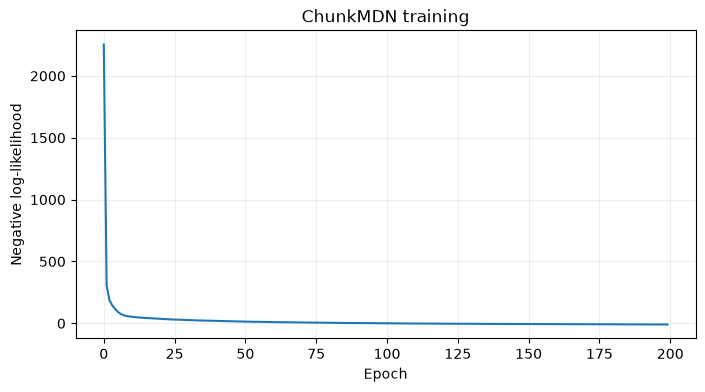

In [34]:
plt.figure(figsize=(8, 4))

plt.plot(mdn_loss_history)

plt.xlabel("Epoch")
plt.ylabel("Negative log-likelihood")
plt.title("ChunkMDN training")
plt.grid(alpha=0.2)
plt.show()

In [35]:
test_obs = torch.tensor(
    [[0.0, 0.0, 0.0, 1.0]],
    dtype=torch.float32,
)

chunk_mdn.eval()

with torch.no_grad():
    dist = chunk_mdn(test_obs)

    weights = dist.mixture_distribution.probs[0]

    means = (
        dist.component_distribution.base_dist.loc[0]
        .reshape(2, HORIZON, 2)
    )

    samples = (
        dist.sample((100,))
        .reshape(100, HORIZON, 2)
    )

print("Mixture weights:", weights.numpy())
print("Component means:", means.shape)

Mixture weights: [0.99748945 0.00251056]
Component means: torch.Size([2, 8, 2])


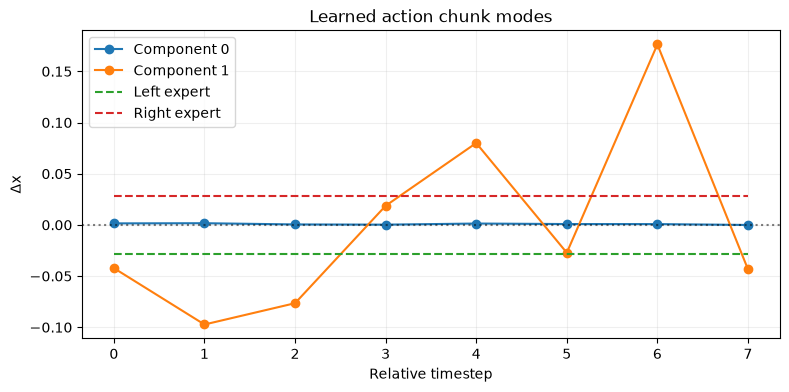

In [36]:
plt.figure(figsize=(9, 4))

for k in range(2):
    plt.plot(
        means[k, :, 0].numpy(),
        "-o",
        label=f"Component {k}",
    )

plt.plot(
    left_chunk[:, 0],
    "--",
    label="Left expert",
)

plt.plot(
    right_chunk[:, 0],
    "--",
    label="Right expert",
)

plt.axhline(
    0,
    color="black",
    linestyle=":",
    alpha=0.5,
)

plt.xlabel("Relative timestep")
plt.ylabel("Δx")
plt.title("Learned action chunk modes")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [37]:
def simulate_chunk(start, chunk):
    position = start.copy()
    positions = [position.copy()]

    for action in chunk:
        position = step(position, action)
        positions.append(position.copy())

    return np.asarray(positions)

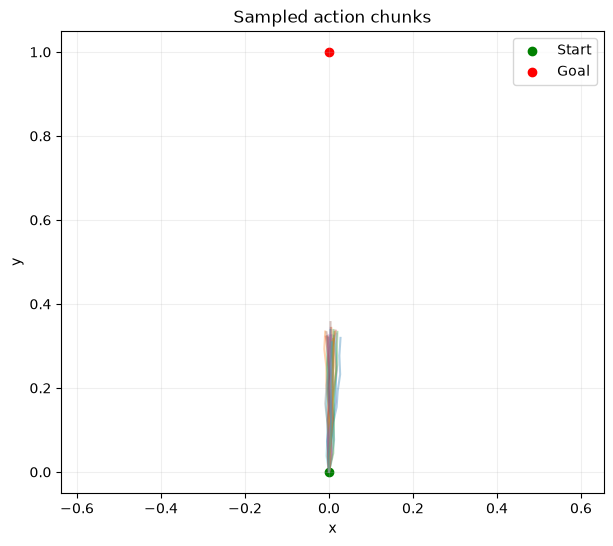

In [38]:
with torch.no_grad():
    dist = chunk_mdn(test_obs)

    sampled_chunks = (
        dist.sample((30,))
        .reshape(30, HORIZON, 2)
        .numpy()
    )

plt.figure(figsize=(7, 6))

for chunk in sampled_chunks:
    positions = simulate_chunk(START, chunk)

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.35,
    )

plt.scatter(*START, color="green", label="Start")
plt.scatter(*GOAL, color="red", label="Goal")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Sampled action chunks")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Debugging policy

In [39]:
torch.manual_seed(42)

chunk_mdn_init = ChunkMDN(
    horizon=HORIZON,
    n_components=2,
    hidden_dim=128,
    scale=0.003,
)

# Initialize the MDN to have the means of the two components match the left and right expert chunks
with torch.no_grad():
    chunk_mdn_init.mean_head.weight.zero_()

    initial_means = np.stack([
        left_chunk,
        right_chunk,
    ])

    chunk_mdn_init.mean_head.bias.copy_(
        torch.tensor(
            initial_means.reshape(-1),
            dtype=torch.float32,
        )
    )

    chunk_mdn_init.logits_head.weight.zero_()
    chunk_mdn_init.logits_head.bias.zero_()

In [40]:
chunk_mdn_init.eval()

with torch.no_grad():
    dist = chunk_mdn_init(test_obs)

    weights = dist.mixture_distribution.probs[0]

    means = (
        dist.component_distribution.base_dist.loc[0]
        .reshape(2, HORIZON, 2)
    )

print("Initial weights:", weights.numpy())

print(
    "Left mean error:",
    torch.norm(
        means[0] - torch.tensor(left_chunk)
    ).item(),
)

print(
    "Right mean error:",
    torch.norm(
        means[1] - torch.tensor(right_chunk)
    ).item(),
)

Initial weights: [0.5 0.5]
Left mean error: 3.759290920555543e-09
Right mean error: 3.759290920555543e-09


In [41]:
optimizer = torch.optim.Adam(
    chunk_mdn_init.parameters(),
    lr=1e-4,
)

num_epochs = 200
init_loss_history = []

for epoch in range(num_epochs):
    chunk_mdn_init.train()
    epoch_loss = 0.0

    for batch_obs, batch_chunks in dataloader:
        dist = chunk_mdn_init(batch_obs)

        loss = -dist.log_prob(batch_chunks).mean()

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            chunk_mdn_init.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        epoch_loss += loss.item() * len(batch_obs)

    epoch_loss /= len(dataset)
    init_loss_history.append(epoch_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"NLL: {epoch_loss:.4f}"
        )

Epoch  20 | NLL: -41.7418
Epoch  40 | NLL: -53.2502
Epoch  60 | NLL: -59.1784
Epoch  80 | NLL: -62.3309
Epoch 100 | NLL: -64.4082
Epoch 120 | NLL: -65.8393
Epoch 140 | NLL: -66.8818
Epoch 160 | NLL: -67.6550
Epoch 180 | NLL: -68.2868
Epoch 200 | NLL: -68.8455


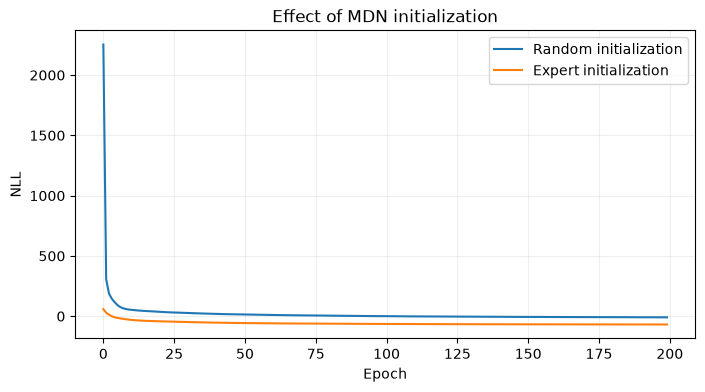

In [42]:
plt.figure(figsize=(8, 4))

plt.plot(
    mdn_loss_history,
    label="Random initialization",
)

plt.plot(
    init_loss_history,
    label="Expert initialization",
)

plt.xlabel("Epoch")
plt.ylabel("NLL")
plt.title("Effect of MDN initialization")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Final weights: [0.49111602 0.50888395]


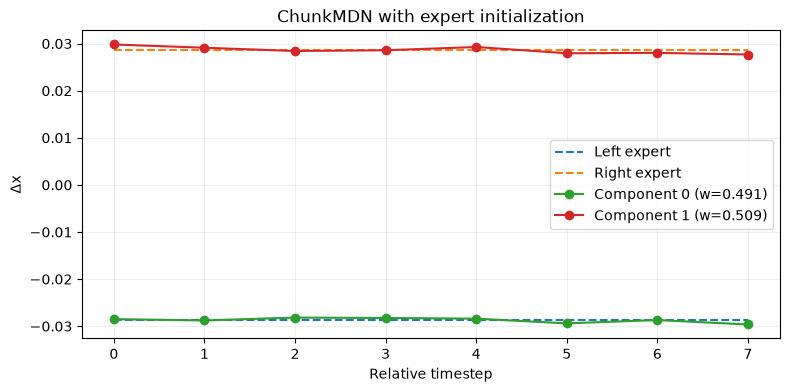

In [43]:
chunk_mdn_init.eval()

with torch.no_grad():
    dist = chunk_mdn_init(test_obs)

    weights = dist.mixture_distribution.probs[0].numpy()

    means = (
        dist.component_distribution.base_dist.loc[0]
        .reshape(2, HORIZON, 2)
        .numpy()
    )

print("Final weights:", weights)

plt.figure(figsize=(9, 4))

plt.plot(
    left_chunk[:, 0],
    "--",
    label="Left expert",
)

plt.plot(
    right_chunk[:, 0],
    "--",
    label="Right expert",
)

for k in range(2):
    plt.plot(
        means[k, :, 0],
        "-o",
        label=f"Component {k} (w={weights[k]:.3f})",
    )

plt.xlabel("Relative timestep")
plt.ylabel("Δx")
plt.title("ChunkMDN with expert initialization")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Compare ChunkingMLP vs ChunkMDN

In [44]:
def stochastic_chunked_rollout(
    model,
    start,
    goal,
    horizon=8,
    execution_horizon=8,
    max_steps=100,
    goal_tolerance=0.05,
):
    assert 1 <= execution_horizon <= horizon

    position = start.copy()

    positions = [position.copy()]
    actions = []

    model.eval()

    while len(actions) < max_steps:
        if reached_goal(position, goal, goal_tolerance):
            break

        observation = make_observation(position, goal)

        obs_tensor = torch.tensor(
            observation,
            dtype=torch.float32,
        ).unsqueeze(0)

        with torch.no_grad():
            dist = model(obs_tensor)

            chunk = (
                dist.sample()[0]
                .reshape(horizon, 2)
                .numpy()
            )

        for action in chunk[:execution_horizon]:
            if len(actions) >= max_steps:
                break

            position = step(position, action)

            actions.append(action.copy())
            positions.append(position.copy())

            if reached_goal(position, goal, goal_tolerance):
                break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions).reshape(-1, 2),
    }

In [45]:
torch.manual_seed(123)

mdn_results = {}

for E in [1, 2, 4, 8]:
    evaluations = []
    trajectories = []

    for start, goal in test_tasks:
        trajectory = stochastic_chunked_rollout(
            chunk_mdn_init,
            start,
            goal,
            horizon=HORIZON,
            execution_horizon=E,
        )

        evaluation = evaluate_trajectory(
            trajectory,
            goal,
        )

        evaluations.append(evaluation)
        trajectories.append(trajectory)

    mdn_results[E] = {
        "success_rate": np.mean([
            e["success"] for e in evaluations
        ]),
        "collision_rate": np.mean([
            e["collision"] for e in evaluations
        ]),
        "trajectories": trajectories,
    }

    print(
        f"E={E} | "
        f"Success: {mdn_results[E]['success_rate']:.1%} | "
        f"Collision: {mdn_results[E]['collision_rate']:.1%}"
    )

E=1 | Success: 54.0% | Collision: 37.0%
E=2 | Success: 66.0% | Collision: 17.0%
E=4 | Success: 63.0% | Collision: 30.0%
E=8 | Success: 58.0% | Collision: 20.0%


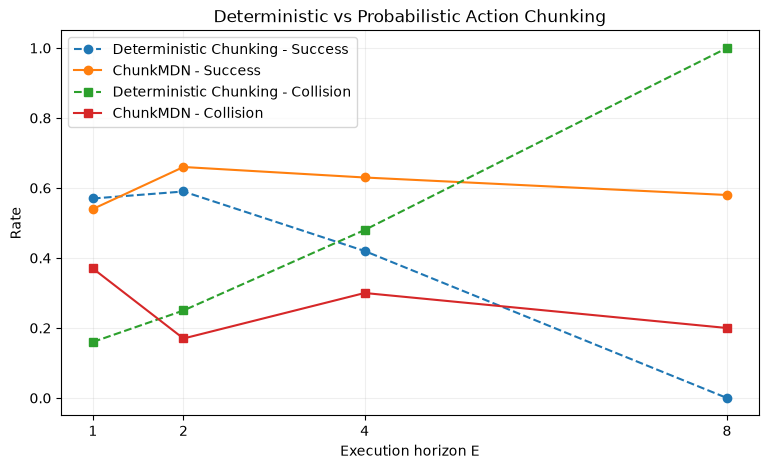

In [46]:
plt.figure(figsize=(9, 5))

E_values = [1, 2, 4, 8]

plt.plot(
    E_values,
    [results[E]["success_rate"] for E in E_values],
    "--o",
    label="Deterministic Chunking - Success",
)

plt.plot(
    E_values,
    [mdn_results[E]["success_rate"] for E in E_values],
    "-o",
    label="ChunkMDN - Success",
)

plt.plot(
    E_values,
    [results[E]["collision_rate"] for E in E_values],
    "--s",
    label="Deterministic Chunking - Collision",
)

plt.plot(
    E_values,
    [mdn_results[E]["collision_rate"] for E in E_values],
    "-s",
    label="ChunkMDN - Collision",
)

plt.xlabel("Execution horizon E")
plt.ylabel("Rate")
plt.title("Deterministic vs Probabilistic Action Chunking")
plt.xticks(E_values)
plt.legend()
plt.grid(alpha=0.2)
plt.show()

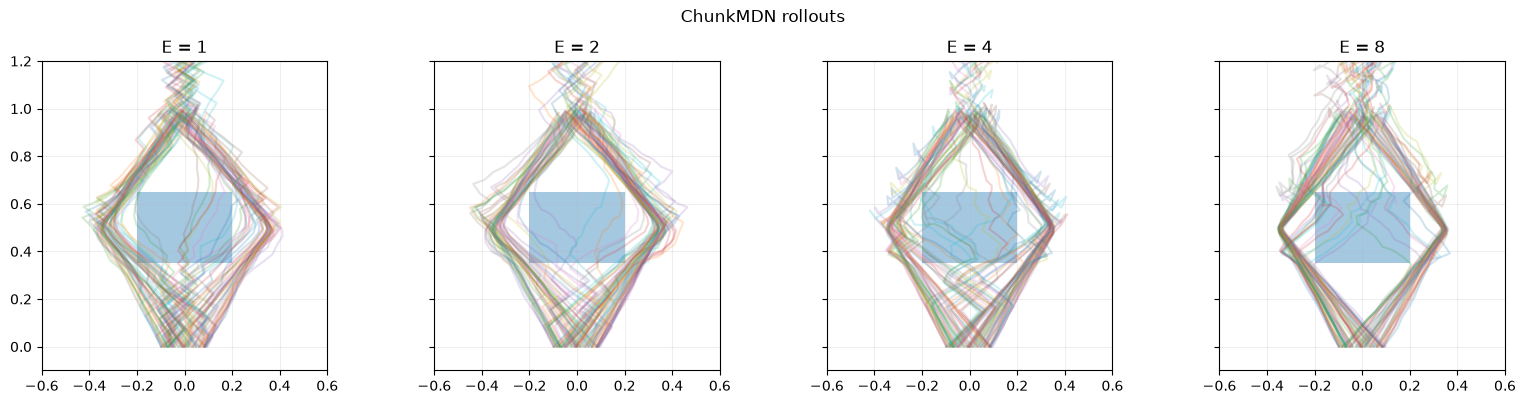

In [47]:
from robot_learning_playground.point_robot import OBSTACLE

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    sharex=True,
    sharey=True,
)

for ax, E in zip(axes, [1, 2, 4, 8]):
    for trajectory in mdn_results[E]["trajectories"]:
        positions = trajectory["positions"]

        ax.plot(
            positions[:, 0],
            positions[:, 1],
            alpha=0.2,
        )

    rect = plt.Rectangle(
        (OBSTACLE["xmin"], OBSTACLE["ymin"]),
        OBSTACLE["xmax"] - OBSTACLE["xmin"],
        OBSTACLE["ymax"] - OBSTACLE["ymin"],
        alpha=0.4,
    )

    ax.add_patch(rect)

    ax.set_title(f"E = {E}")
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.1, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.suptitle("ChunkMDN rollouts")
plt.tight_layout()
plt.show()

In [48]:
def sample_chunk_mode_mean(model, observation, horizon=8):
    obs = torch.as_tensor(
        observation, dtype=torch.float32
    ).unsqueeze(0)

    with torch.no_grad():
        dist = model(obs)

        k = dist.mixture_distribution.sample().item()

        means = dist.component_distribution.base_dist.loc[0]

        chunk = means[k].reshape(horizon, 2)

    return chunk.numpy()

In [55]:
def mode_mean_chunked_rollout(
    model,
    start,
    goal,
    horizon=8,
    execution_horizon=8,
    max_steps=100,
    goal_tolerance=0.05,
):
    assert 1 <= execution_horizon <= horizon

    position = start.copy()

    positions = [position.copy()]
    actions = []

    model.eval()

    while len(actions) < max_steps:
        if reached_goal(position, goal, goal_tolerance):
            break

        observation = make_observation(position, goal)

        obs_tensor = torch.tensor(
            observation,
            dtype=torch.float32,
        ).unsqueeze(0)

        chunk = sample_chunk_mode_mean(
            model, observation, horizon
        )

        for action in chunk[:execution_horizon]:
            if len(actions) >= max_steps:
                break

            position = step(position, action)

            actions.append(action.copy())
            positions.append(position.copy())

            if reached_goal(position, goal, goal_tolerance):
                break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions).reshape(-1, 2),
    }

In [56]:
torch.manual_seed(123)

mdn_results = {}

for E in [1, 2, 4, 8]:
    evaluations = []
    trajectories = []

    for start, goal in test_tasks:
        trajectory = mode_mean_chunked_rollout(
            chunk_mdn_init,
            start,
            goal,
            horizon=HORIZON,
            execution_horizon=E,
        )

        evaluation = evaluate_trajectory(
            trajectory,
            goal,
        )

        evaluations.append(evaluation)
        trajectories.append(trajectory)

    mdn_results[E] = {
        "success_rate": np.mean([
            e["success"] for e in evaluations
        ]),
        "collision_rate": np.mean([
            e["collision"] for e in evaluations
        ]),
        "trajectories": trajectories,
    }

    print(
        f"E={E} | "
        f"Success: {mdn_results[E]['success_rate']:.1%} | "
        f"Collision: {mdn_results[E]['collision_rate']:.1%}"
    )

E=1 | Success: 53.0% | Collision: 32.0%
E=2 | Success: 63.0% | Collision: 21.0%
E=4 | Success: 66.0% | Collision: 23.0%
E=8 | Success: 60.0% | Collision: 21.0%


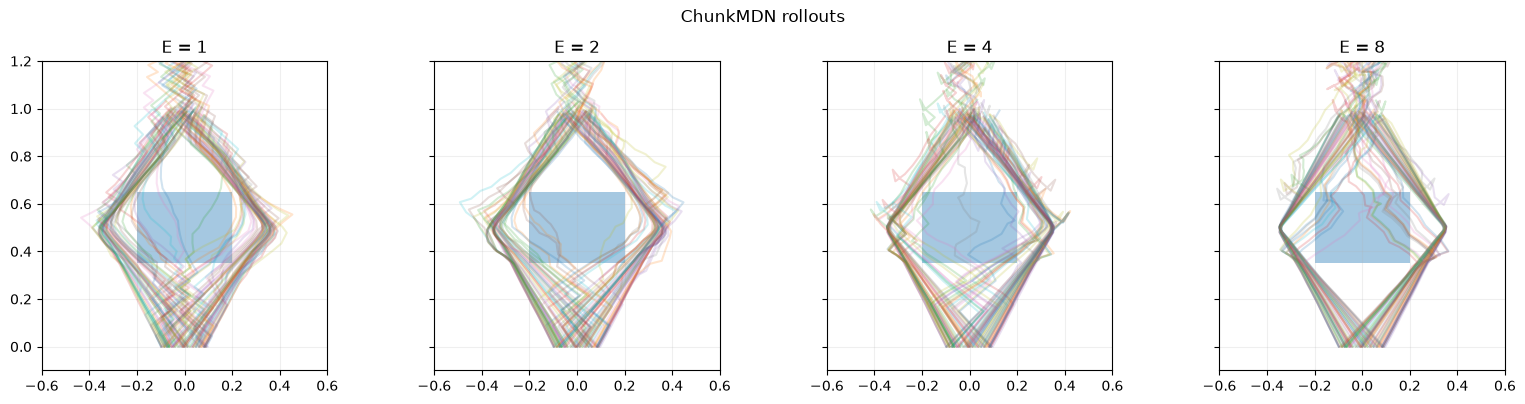

In [57]:
from robot_learning_playground.point_robot import OBSTACLE

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    sharex=True,
    sharey=True,
)

for ax, E in zip(axes, [1, 2, 4, 8]):
    for trajectory in mdn_results[E]["trajectories"]:
        positions = trajectory["positions"]

        ax.plot(
            positions[:, 0],
            positions[:, 1],
            alpha=0.2,
        )

    rect = plt.Rectangle(
        (OBSTACLE["xmin"], OBSTACLE["ymin"]),
        OBSTACLE["xmax"] - OBSTACLE["xmin"],
        OBSTACLE["ymax"] - OBSTACLE["ymin"],
        alpha=0.4,
    )

    ax.add_patch(rect)

    ax.set_title(f"E = {E}")
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.1, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.suptitle("ChunkMDN rollouts")
plt.tight_layout()
plt.show()

## Conclusions

In this notebook, we extended single-step behavior cloning to action
chunking and probabilistic sequence prediction.

### Main findings

1. **Deterministic action chunking does not solve multimodality.**
   An MLP trained with MSE tends to predict the conditional mean
   of different expert strategies.

2. **Probabilistic action chunking can represent multiple strategies.**
   A ChunkMDN models a mixture distribution over complete action
   sequences instead of individual actions.

3. **Training multimodal distributions is not trivial.**
   Random initialization caused component collapse. Expert-informed
   initialization helped the model recover the two strategies.

4. **Execution horizon matters.**
   Open-loop execution and frequent replanning introduce different
   trade-offs between feedback and temporal consistency.

5. **Multimodality does not guarantee temporal consistency.**
   Sampling a new action chunk at each replanning step can cause
   switching between strategies.

6. **Removing Gaussian sampling noise was not sufficient.**
   The observed rollout performance remained similar, suggesting
   that other factors, including mode switching and prediction
   errors, contribute to instability.

### Connection to modern robot learning

Action chunking is a central component of modern imitation learning
policies.

- ACT combines action chunking, a conditional VAE, and Transformers.
- Diffusion Policy learns a conditional generative distribution
  over action sequences.
- Modern VLA policies such as pi0 generate action chunks using
  more expressive generative modeling techniques.

### Next step

We will study latent-variable generative models, starting with
Variational Autoencoders (VAEs), and then extend them to
Conditional VAEs (CVAEs).

Our goal is to understand how a continuous latent variable can
represent different possible action sequences without explicitly
defining a fixed number of mixture components.